# **Part B — Pizza Review Analysis**

## **1. Problem Statement**

The objective of this project is to develop a deep learning model capable of accurately classifying sentiment in pizza reviews (positive, neutral, or negative) using text data. The dataset contains natural language reviews that are informal, mixed-language, and linguistically complex, making sentiment classification challenging due to sarcasm, negation, and ambiguous phrasing.

---

## **2. Plan**

The following approach was implemented:

* Data Inspection
* Preprocess text data (cleaning, tokenisation, padding)
* Build a **baseline SimpleRNN model** for initial benchmarking
* Develop an improved **LSTM model** to better capture long-term dependencies in text
* Train both models 
* Evaluate performance using:

  * Accuracy (train, validation, test)
  * F1-score
  * Test loss
* Perform **error analysis** to identify misclassification patterns and limitations

---

## **3. Hypothesis**

It is hypothesised that the LSTM model will outperform the SimpleRNN baseline in sentiment classification because LSTM networks are better at capturing long-term dependencies and contextual meaning in sequential text data.

However, it is expected that both models may still struggle with:

* Subtle or indirect sentiment expressions
* Complex sentence structures involving negation
* Mixed or ambiguous emotional phrases
* Short reviews lacking strong sentiment signals

---

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import random

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

SEED = 88
random.seed(SEED)
np.random.seed(SEED)

## **1.1 Load Data**


In [49]:
df = pd.read_csv("C:/Users/yyuel/OneDrive - Singapore Polytechnic/Pizza reviews.csv")

print("=== Dataset Overview ===")
print(f"Shape: {df.shape}")
print(f"\nColumn Types:")
print(df.dtypes)
print(f"\nFirst 5 rows:")
df.head()

=== Dataset Overview ===
Shape: (902, 4)

Column Types:
Review                                                                                   object
Score                                                                                    object
Are there ways for you to generate more data? Spliting up sentences, would that help?    object
Language                                                                                 object
dtype: object

First 5 rows:


,Review,Score,"Are there ways for you to generate more data? Spliting up sentences, would that help?",Language
0,Disgusting.,1,NaN,English
1,Loved the sambal kick!,10,NaN,English
2,Loved the sambal kick!,0.1,NaN,English
3,Loved the sambal kick!,5,NaN,English
4,"Satay on pizza? Surprisingly worked. Tasty, un...",7,NaN,English


**Dataset Overview**

After loading the dataset, several observations were identified during the initial inspection:

- The dataset contains **902 rows** and **4 columns**
- Most columns are stored as `object` data types and require cleaning or conversion
- The `Score` column is currently stored as text (`object`) instead of numeric values
- One column contains a very long question:

  *"Are there ways for you to generate more data? Splitting up sentences, would that help?"*

  This column appears unnecessary for sentiment analysis and may be removed
---

## **1.2 Data Inspection**

In [50]:
# 1. Check Missing Values
print("=== Missing Values ===")
print(df.isnull().sum())
print()

# 2. Check Duplicate Rows
duplicate_count = df.duplicated().sum()
print("=== Duplicate Rows ===")
print(f"Number of duplicate rows: {duplicate_count}")
print()

# 3. Language Distribution
print("=== Language Distribution ===")
print(df['Language'].value_counts())
print()

=== Missing Values ===
Review                                                                                     0
Score                                                                                      2
Are there ways for you to generate more data? Spliting up sentences, would that help?    900
Language                                                                                   0
dtype: int64

=== Duplicate Rows ===
Number of duplicate rows: 45

=== Language Distribution ===
Language
English                      492
Malay                        402
Chinese                        3
Guga                           2
Come on ...                    1
You cannot be serious ...      1
Nippon                         1
Name: count, dtype: int64



In [51]:
# Score Distribution
print(df['Score'].describe())
print()

# Convert to numeric first
df['Score'] = pd.to_numeric(df['Score'], errors='coerce')

print("\nValue counts (rounded):")
print(df['Score'].round().value_counts().sort_index())

count     900
unique    291
top       0.1
freq       23
Name: Score, dtype: object


Value counts (rounded):
Score
-42.0        1
 0.0       144
 1.0       110
 2.0        16
 3.0        11
 4.0        46
 5.0       153
 6.0        51
 7.0        18
 8.0        21
 9.0        55
 10.0      270
 1010.0      1
Name: count, dtype: int64


**Invalid values exist**
  - `-42.0` and `1010.0` are impossible sentiment scores
  - These are likely data entry or formatting errors

**Inconsistent scoring**
  - Most scores are between 0 and 10
  - But there are unusual values like `0.1`, showing inconsistent input format

**Skewed distribution**

Very high frequency at extreme values:
  - 10.0 → 270 entries
  - 5.0 → 153 entries
  - 0.0 → 144 entries

- The dataset is imbalanced, with more extreme values (0, 5, 10)
- This may cause the model to bias toward dominant classes
- Balanced distribution improves model fairness and performance

Therefore, distribution should be monitored, and class grouping or resampling can be considered if needed.

**Why This Is a Problem**

- The model may learn incorrect patterns from invalid values
- Outliers like `-42.0` and `1010.0` can distort training
- Inconsistent scoring makes it harder for the model to learn a clear relationship between text and sentiment
- Strong bias toward extreme values may reduce the model’s ability to predict moderate sentiments

---

## **1.3 Sample Reviews**


- Read actual reviews - not just statistics to catch issues like mixed languages, HTML tags, emojis, and nonsense entries.

In [52]:
print("=== Sample Reviews (with Scores) ===")
sample = df[['Review', 'Score']].sample(10, random_state=42)
for i, (_, row) in enumerate(sample.iterrows(), 1):
    print(f"Review {i} | Score: {row['Score']}")
    print(row['Review'])
    print("-" * 60)

=== Sample Reviews (with Scores) ===
Review 1 | Score: 1.0
Disgusting.
------------------------------------------------------------
Review 2 | Score: 9.86
Perfectly cooked crust with exciting, rich toppings.
------------------------------------------------------------
Review 3 | Score: 1.0
Pizza was greasy and unpleasant to eat.
------------------------------------------------------------
Review 4 | Score: 0.55
Awful pizza with burnt, chewy crust.
------------------------------------------------------------
Review 5 | Score: 9.0
Perfect crust.
------------------------------------------------------------
Review 6 | Score: 9.97
Terbaik! Topping segar dan roti garing. Fusion pizza yang sangat sedap.
------------------------------------------------------------
Review 7 | Score: 0.0
Rasa yang tak boleh diterima.
------------------------------------------------------------
Review 8 | Score: 0.16
So wrong it’s right.
------------------------------------------------------------
Review 9 | Scor

**Sample Review Observations**

- The dataset contains both **positive and negative reviews**

- A few reviews appear unclear or nonsensical, such as:
  - *"So wrong it’s right."*
  
- The dataset also contains multilingual reviews, including both **English and Malay**

These observations suggest that the dataset may contain noisy, inconsistent, or low-information reviews.

## **1.4 Duplicate Review Check**


In [53]:
n_dupes = df.duplicated(subset='Review').sum()
print(f"=== Duplicate Check ===")
print(f"Duplicate reviews found: {n_dupes}")

print("\nSample duplicate entries:")
print(df[df.duplicated(subset='Review', keep=False)][['Review', 'Score']].head(6))

=== Duplicate Check ===
Duplicate reviews found: 102

Sample duplicate entries:
                                               Review  Score
0                                         Disgusting.    1.0
1                              Loved the sambal kick!   10.0
2                              Loved the sambal kick!    0.1
3                              Loved the sambal kick!    5.0
9   The sambal slice burned my mouth in the best w...    8.0
10                                        Just weird.    2.0


**Duplicate Review analysis**

- The same reviewhave **different sentiment scores**
  - Example: *"Loved the sambal kick!" → 10.0 / 5.0 / 0.1*
- This is not a normal duplicate case
- It indicates inconsistent labeling (noise in data)


**Why This Is Important**

- If not handled properly, the model will:
  - Get confused by the same input having different labels
  - Learn incorrect patterns
  - Produce lower accuracy and unstable predictions

- This is especially important for RNN sentiment analysis, where consistency in text-label mapping is crucial
---

## **Data Inspection Summary**


**1. Overview of Dataset Content**

The dataset contains **902 rows and 4 columns**, consisting of customer pizza reviews with associated sentiment scores.

- Reviews include both **positive and negative sentiments**
- Text data is mainly in **English and Malay**
- Some entries contain unclear or nonsensical text, indicating natural noise in user-generated data

This suggests the dataset is realistic but requires preprocessing before use in machine learning models.

---

**2. Missing Values and Irrelevant Columns**

- The Score column has 2 missing values, which must be removed because labels are required for supervised learning
- One column contains a long question unrelated to sentiment analysis and should be dropped

These steps are necessary to ensure only meaningful features are used for modelling.

---

**3. Duplicate Reviews and Their Impact**

The dataset contains:
- **45 fully duplicated rows**
- **102 duplicated review texts**

More importantly, some identical reviews have **different scores**, which creates label inconsistency.

**Why this is a problem:**

- The same input text appears with different sentiment labels
- This confuses the model during training
- It introduces noise and reduces learning accuracy

**What should be done:**

- Fully duplicated rows to removed
- Duplicate reviews to grouped together and their scores were averaged so each review has one consistent label

---

**4. Language Distribution and Handling**

The dataset contains:
- English (majority)
- Malay (large secondary group)
- Very small and noisy labels such as Chinese, “Guga”, and invalid text entries

**Why this matters:**

- Rare or incorrect language labels introduce noise
- They do not contribute meaningful training signal

**Decision:**

- Only English and Malay reviews to retaine
- This ensures sufficient data size while removing noise

---

**5. Score Column Analysis and Class Distribution**

The score column shows:
- Valid range mostly between **0 and 10**
- Presence of invalid outliers such as **-42.0 and 1010.0**
- Inconsistent formats like decimal values (e.g., 0.1, 9.86)
- Heavy concentration of extreme values (0, 5, 10)

**Why this is important:**

Yes, score distribution matters because:
- The dataset is not perfectly balanced
- Extreme values dominate the dataset
- This may cause the model to become biased toward strong positive or negative predictions
- Poor balance reduces ability to learn subtle sentiment differences

---

**6. Summary of Cleaning Requirements**

Based on the inspection, the dataset requires:

- Removal of missing values in Score
- Deletion of irrelevant columns
- Handling of duplicate reviews (aggregation of scores)
- Filtering of invalid or noisy language labels
- Removal of invalid score values and outliers
- Standardisation of score format

---

**Final Insight**

The dataset is suitable for sentiment analysis, but contains **noise, duplicates, and inconsistencies**. Proper cleaning is essential to ensure the model learns accurate and unbiased patterns from the data.

## **2.1 Data Cleaning**


**1. Remove Irrelevant Column**

In [54]:
# Drop unnecessary column
df = df.drop(columns=[col for col in df.columns if 'Are there ways' in col])

This column is unrelated to sentiment analysis and contains mostly missing values. It does not contribute to model training and is therefore removed to reduce noise.

**2. Handle Missing Values**|

In [55]:
# Remove rows with missing scores
df = df.dropna(subset=['Score'])

The Score column is the target label for prediction. Missing values cannot be used in supervised learning, so these rows are removed.

**3. Convert Score and Remove Invalid Values**

In [56]:
# Convert score to numeric
df['Score'] = pd.to_numeric(df['Score'], errors='coerce')

# Keep valid range only (0–10)
df = df[(df['Score'] >= 0) & (df['Score'] <= 10)]

The dataset contains invalid and inconsistent values (e.g. -42, 1010, and decimals). Cleaning ensures all scores are within a valid sentiment range and properly formatted for modelling.

**4. Clean Language Column**

In [57]:
# Keep only English and Malay reviews
df = df[df['Language'].isin(['English', 'Malay'])]

- Only **English and Malay** reviews were kept based on the final language distribution:
  - English: 435
  - Malay: 346
- Malay reviews were retained because they make up a large portion of the dataset. Removing them would significantly reduce the amount of training data and may cause the model to become biased toward English only.
- Removed other languages (e.g., Chinese, Japanese, Guga) due to very small sample sizes, which could add noise and not support meaningful model training

Keeping both languages helps:
- Maintain a balanced dataset size
- Improve model generalisation across different user inputs
- Reduce the risk of overfitting to only English text
Therefore, both English and Malay were kept to ensure the model learns from a more diverse and realistic dataset.

**5. Handle Duplicate Reviews**

In [58]:
# 5. Handle duplicate reviews (combine them)
df = df.groupby('Review', as_index=False).agg({
    'Score': 'mean',
    'Language': 'first'
})

**Recheck of the review after grouping**

In [59]:
print(df['Review'].value_counts())

Review
A beautifully bold and flavorful fusion pizza experience.             1
Sambal yang pedas dan mayo yang creamy sangat menarik.                1
Sambal and mayo were there, but didn’t shine.                         1
Sambal dan satay buat pizza ini sedap dan unik.                       1
Sambal gave a mild kick, but overall average.                         1
                                                                     ..
Mayo was too sweet. Didn't enjoy it at all.                           1
Mayo? Surprisingly smooth. Every bite felt like fusion done right.    1
Mayonis terlalu banyak buat rasa jadi berat.                          1
Mayonis terlalu banyak, buat pizza jadi berat dan berminyak.          1
Wow! Rasa sambal pedas dan mayo creamy. Pizza fusion yang hebat.      1
Name: count, Length: 781, dtype: int64


Duplicate reviews with different scores were combined into a single entry so that each unique review appears only once in the dataset.

When duplicates exist, the **average (mean) score** is calculated to represent a single consistent sentiment value for that review.

This ensures:
- Each review has only one final label  
- Conflicting scores are resolved fairly using the mean  
- The dataset is more consistent and suitable for training 
--- 

**Cleaning Summary**

After cleaning:
- Irrelevant columns were removed
- Missing values were dropped
- Invalid and out-of-range scores were filtered
- Only English and Malay reviews were kept
- Duplicate reviews were merged into a single entry with averaged scores

The dataset is now clean, consistent, and ready for feature engineering and model training.

**Final dataset check**

In [60]:
# Final Dataset Check
print("=== Final Cleaned Dataset Summary ===")
print(f"Final Shape: {df.shape}\n")

print("Column Data Types:")
print(df.dtypes, "\n")

print("Missing Values:")
print(df.isnull().sum(), "\n")

# Duplicate check
print("Remaining Duplicate Reviews:")
print(df.duplicated(subset=['Review']).sum(), "\n")

print("Final Language Distribution:")
print(df['Language'].value_counts())

=== Final Cleaned Dataset Summary ===
Final Shape: (781, 3)

Column Data Types:
Review       object
Score       float64
Language     object
dtype: object 

Missing Values:
Review      0
Score       0
Language    0
dtype: int64 

Remaining Duplicate Reviews:
0 

Final Language Distribution:
Language
English    435
Malay      346
Name: count, dtype: int64


In [61]:
print("Final Score Statistics:")
print(df['Score'].describe(), "\n")
print("\nValue counts (rounded):")
print(df['Score'].round().value_counts().sort_index())

Final Score Statistics:
count    781.000000
mean       5.921041
std        3.659624
min        0.000000
25%        2.333333
50%        5.450000
75%        9.770000
max       10.000000
Name: Score, dtype: float64 


Value counts (rounded):
Score
0.0      84
1.0     102
2.0      11
3.0       7
4.0      40
5.0     148
6.0      44
7.0      15
8.0      14
9.0      48
10.0    268
Name: count, dtype: int64


## Final Dataset Summary

**781 rows × 3 columns** (Review, Score, Language) — clean, no nulls, no duplicates.

**Languages:** English 435 · Malay 346

**Scores:** 
- Mean 5.92 
- Median 5.45 
- Range 0–10
Top values: 10.0 (268), 5.0 (148), 1.0 (102)

Slight positive skew — account for this during model training.

## **2.2 Visualisations - Original Data**


**1. Score Distribution**

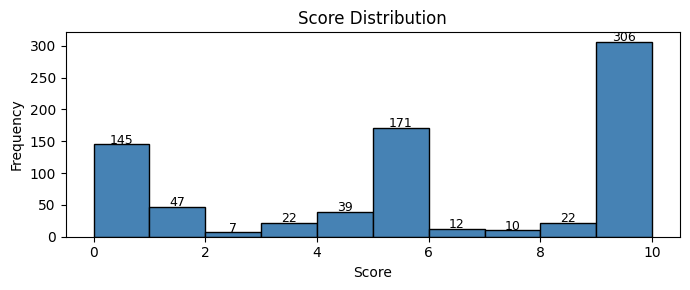

In [62]:
plt.figure(figsize=(7,3))
counts, edges, bars = plt.hist(df['Score'], bins=10, color='steelblue', edgecolor='black')
for bar, count in zip(bars, counts):
    if count > 0:
        plt.text(bar.get_x() + bar.get_width()/2, count + 1, int(count), ha='center', fontsize=9)
plt.title("Score Distribution")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**What the chart shows:**
- Massive spike at **10** (~305) and **0–1** (~145) — classic U-shape
- **5** is the only middle score with decent volume (~170)
- Scores 2–4 and 6–9 are very sparse (under 50 each)

This means people rarely give "in-between" scores — they either love it, hate it, or sit exactly at the middle.

**Why It Matters for Modelling**
- If scores are kept as-is (0–10), model will be **terrible** at predicting sparse scores like 3.0 or 7.0 — not enough examples to learn from
- The model will just learn to predict 10 most of the time (majority class problem)
- This confirms grouping into Negative/Neutral/Positive is the right move
---

**2. Language Distribution**

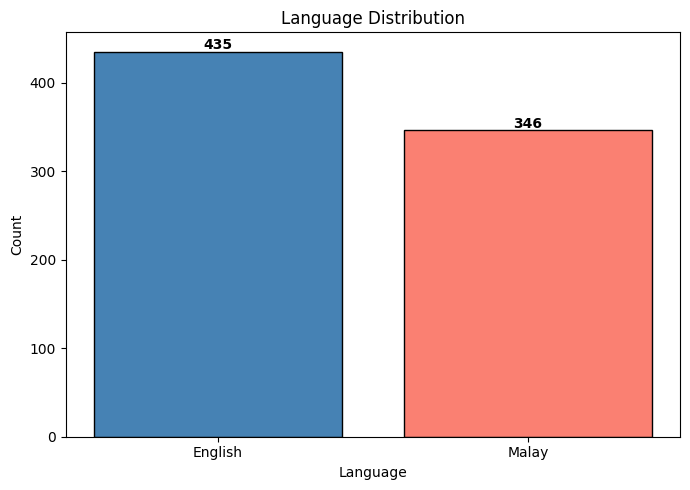

In [63]:
lang_counts = df['Language'].value_counts()
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(lang_counts.index, lang_counts.values, color=['steelblue', 'salmon'], edgecolor='black')
for bar, count in zip(bars, lang_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, count + 3, str(count), ha='center', fontweight='bold')
ax.set_title("Language Distribution")
ax.set_xlabel("Language")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

- English: ~435, Malay: ~346
- Roughly 56% / 44% split — pretty balanced

**Why It Matters**

- No severe language imbalance, so model won't be biased toward English
- But still need to preprocess them differently — Malay stopwords ≠ English stopwords
---

## **3. Preprocessing**

## **3.1 Sentiment Grouping**

### **Hypothesis**

We hypothesised that the dataset may have an uneven distribution of sentiment classes, which could bias the model toward the majority class (likely Positive). We also expected possible differences in sentiment distribution across languages (English vs Malay), which may introduce hidden bias during training.

---

### **Experiment**

We analysed the sentiment labels in the dataset by:

* Counting the number of Negative, Neutral, and Positive reviews
* Splitting the sentiment counts by language (English vs Malay)
* Comparing class proportions to detect imbalance or skew

---

In [64]:
# Group scores into sentiment
def group_score(score):
    if score <= 3:
        return 'Negative'
    elif score <= 6:
        return 'Neutral'
    else:
        return 'Positive'

df['Sentiment'] = df['Score'].apply(group_score)

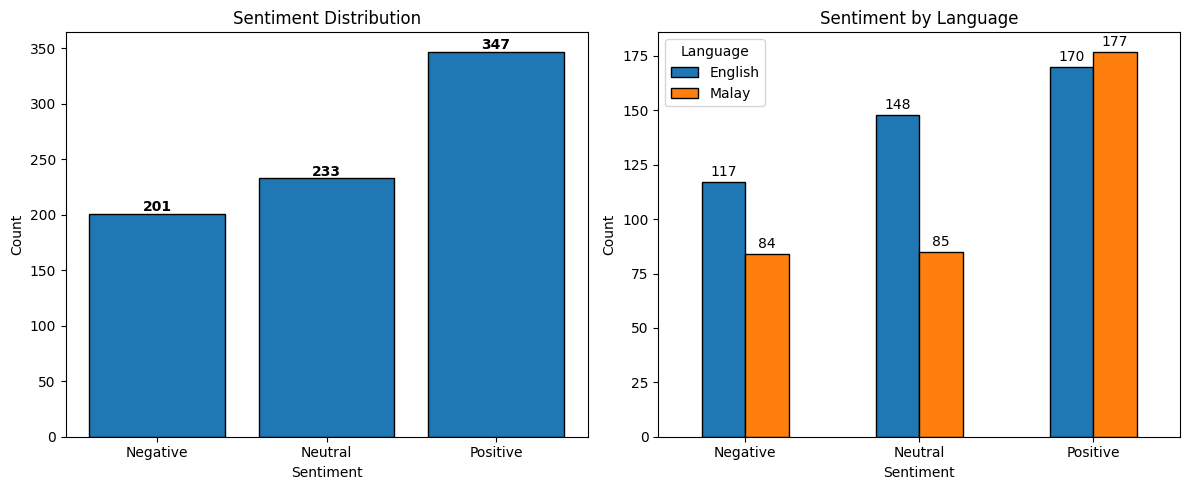

In [65]:
# Plot
order = ['Negative', 'Neutral', 'Positive']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Sentiment distribution
sentiment_counts = df['Sentiment'].value_counts().reindex(order)
bars = axes[0].bar(order, sentiment_counts.values, edgecolor='black')
for bar, count in zip(bars, sentiment_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, count + 2, str(count), ha='center', fontweight='bold')
axes[0].set_title("Sentiment Distribution")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Count")

# Sentiment by language
lang_sentiment = df.groupby(['Sentiment', 'Language']).size().unstack().reindex(order)
lang_sentiment.plot(kind='bar', ax=axes[1], edgecolor='black', rot=0)
for container in axes[1].containers:
    axes[1].bar_label(container, padding=2)
axes[1].set_title("Sentiment by Language")
axes[1].set_xlabel("Sentiment")
axes[1].set_ylabel("Count")
axes[1].legend(title='Language')

plt.tight_layout()
plt.show()

### **Results**

**Overall Sentiment Distribution**

* Negative: 201
* Neutral: 233
* Positive: 347
* Positive reviews are 73% higher than Negative reviews
* Dataset shows a **mild class imbalance**

**Sentiment by Language**

* **English:** Negative 117 · Neutral 148 · Positive 170
* **Malay:** Negative 84 · Neutral 85 · Positive 177

Key observation:

* Malay reviews are **heavily skewed toward Positive sentiment**
* English reviews are more evenly distributed across all classes

---

### **Analysis**

The dataset is not severely imbalanced overall, but the dominance of Positive reviews introduces a risk of model bias. A model trained on this distribution may over-predict Positive sentiment, leading to misleadingly high accuracy.

This makes accuracy an unreliable evaluation metric. Instead, a **weighted F1-score** is more appropriate as it accounts for class imbalance.

Additionally, the Malay subset shows a strong positive skew, which may cause the model to associate Malay language patterns with positive sentiment regardless of actual meaning. This introduces a **hidden language-based bias**, meaning performance should also be evaluated separately by language.

To mitigate these issues:

* Use **weighted F1-score instead of accuracy**
* Apply **class weighting (`class_weight='balanced'`) during training**
* Monitor **language-level performance separately**

---

## **3.2 Feature Engineering**

### **Hypothesis**

We hypothesised that simple textual features such as word count and punctuation usage (e.g. exclamation marks) may carry meaningful sentiment signals that can improve model performance beyond raw text alone.

---

### **Experiment**

We extracted additional features from the dataset before model training:

* Word count per review grouped by sentiment
* Exclamation mark frequency grouped by sentiment
  These features were analysed prior to text cleaning to preserve natural writing signals.


In [66]:
# Extract features BEFORE any text cleaning
df['word_count'] = df['Review'].str.split().str.len()
df['has_exclamation'] = df['Review'].str.contains('!').astype(int)
df['review_length'] = df['Review'].apply(len)

print(df.groupby('Sentiment')['word_count'].mean())
print()
print(df.groupby('Sentiment')['has_exclamation'].mean())

Sentiment
Negative     5.631841
Neutral      8.081545
Positive    10.331412
Name: word_count, dtype: float64

Sentiment
Negative    0.000000
Neutral     0.008584
Positive    0.204611
Name: has_exclamation, dtype: float64


### **Results**

**Word Count by Sentiment**

* Clear increasing trend observed: Positive reviews tend to be longer
* Negative reviews are generally shorter and more direct

**Exclamation Rate by Sentiment**

* Exclamation marks appear predominantly in Positive reviews
* Very rare in Neutral and Negative classes

---

### **Analysis**

The results suggest that writing style itself carries sentiment information. Positive reviews are typically more expressive and detailed, while negative reviews are shorter and more direct.

Exclamation marks act as a strong sentiment indicator, especially for positive emotions. Since both word count and punctuation patterns show consistent separation across classes, they are useful engineered features.

These features were extracted before text cleaning to ensure that stylistic signals were not removed during preprocessing.

---

## **3.3 Basic Text Cleaning**

### **Hypothesis**

We hypothesised that standardising text through basic cleaning would reduce noise and improve tokenisation quality, leading to better model learning and generalisation.

---

### **Experiment**

A preprocessing pipeline was applied to all review texts before tokenisation:

* Converted text to lowercase
* Replaced hyphens with spaces
* Removed punctuation, numbers, and special characters
* Removed extra whitespace

In [67]:
def preprocess(text):
    text = text.lower()                        # lowercase
    text = re.sub(r'-', ' ', text)             # hyphens to spaces
    text = re.sub(r'[^a-zA-Z\s]', '', text)   # remove punctuation, numbers, special chars
    text = re.sub(r'\s+', ' ', text).strip()  # remove extra whitespace
    return text

df['cleaned'] = df['Review'].apply(preprocess)
print(df[['Review', 'cleaned']].head(10))

                                              Review  \
0  A beautifully bold and flavorful fusion pizza ...   
1  A bold, beautiful marriage of flavors that exc...   
2  A creative and well-executed pizza. The sambal...   
3           A decent pizza that didn’t impress much.   
4  A delicious fusion pizza that hits all the rig...   
5  A delightful and unique pizza with amazing Sou...   
6  A delightful explosion of flavors, from the sp...   
7  A fair attempt at fusion pizza, but needs more...   
8  A fantastic twist on pizza with exciting South...   
9  A fresh take on pizza with a delightful sambal...   

                                             cleaned  
0  a beautifully bold and flavorful fusion pizza ...  
1  a bold beautiful marriage of flavors that exci...  
2  a creative and well executed pizza the sambal ...  
3             a decent pizza that didnt impress much  
4  a delicious fusion pizza that hits all the rig...  
5  a delightful and unique pizza with amazing sou... 


### **Results**

* Text became more uniform and consistent after preprocessing
* Vocabulary size was reduced due to removal of noise tokens
* Tokenisation became more stable and less fragmented

---

### **Analysis**

- **Lowercasing** ensures that words like “Good” and “good” are treated as the same token, improving consistency.
- **Hyphen handling** helps separate joined words (e.g., “well-made” → “well made”) so the model can learn each word properly.
- **Removing punctuation and special characters** reduces noise in the dataset and simplifies tokenisation.
- **Removing numbers** avoids irrelevant tokens that do not contribute to sentiment analysis.
- **Whitespace cleaning** ensures clean and consistent spacing between words.

---

## **3.4 Translation — Malay to English**

### **Hypothesis**

We hypothesised that mixing Malay and English text would fragment the vocabulary and reduce model performance due to inconsistent token representations across languages.

---

### **Experiment**

All Malay reviews were translated into English before tokenisation. This was done to unify the dataset into a single language space for consistent learning.

---


In [68]:
from deep_translator import GoogleTranslator

def translate_to_english(text, language):
    if language == 'Malay':
        try:
            return GoogleTranslator(source='ms', target='en').translate(text)
        except:
            return text  # if translation fails, keep original
    return text

df['cleaned'] = df.apply(lambda row: translate_to_english(row['cleaned'], row['Language']), axis=1)

In [69]:
malay_sample = df[df['Language'] == 'Malay'][['Review', 'cleaned', 'Score', 'Sentiment']].head(10)

for i, row in malay_sample.iterrows():
    print(f"ORIGINAL  : {row['Review']}")
    print(f"CLEANED   : {row['cleaned']}")
    print(f"SCORE     : {row['Score']}")
    print(f"SENTIMENT : {row['Sentiment']}")
    print("-" * 80)

ORIGINAL  : Agak hambar.
CLEANED   : rather bland
SCORE     : 4.85
SENTIMENT : Neutral
--------------------------------------------------------------------------------
ORIGINAL  : Agak okay.
CLEANED   : kinda okay
SCORE     : 5.8
SENTIMENT : Neutral
--------------------------------------------------------------------------------
ORIGINAL  : Biasa saja.
CLEANED   : normal
SCORE     : 5.4
SENTIMENT : Neutral
--------------------------------------------------------------------------------
ORIGINAL  : Biasa-biasa sahaja, pizza fusion ni. Rasa sambal dan mayo tak begitu menonjol. Tak ada yang spesial.
CLEANED   : This fusion pizza is normal, the taste of sambal and mayo is not so prominent, nothing special
SCORE     : 5.1
SENTIMENT : Neutral
--------------------------------------------------------------------------------
ORIGINAL  : Biasa-biasa saja, pizza fusion ni. Rasa sambal dan mayo tidak menyerlah. Tidak ada yang menarik.
CLEANED   : This fusion pizza is normal, the taste of sambal an


### **Results**

* Dataset became fully English-based after translation
* Vocabulary was unified, reducing duplicate semantic tokens across languages
* Tokenisation became more consistent across all samples

---

### **Analysis**

Without translation, the model would treat Malay and English words as separate feature spaces, increasing sparsity and weakening learned sentiment patterns.

By translating Malay reviews into English, we reduce vocabulary fragmentation and improve the model’s ability to learn consistent sentiment signals across the entire dataset. However, this may also remove subtle cultural or linguistic nuance present in the original text.

---

## **3.5 Prepare Labels**

In [70]:
# 1. Encode sentiment labels to numbers
le = LabelEncoder()
df['label'] = le.fit_transform(df['Sentiment'])

print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

Label mapping: {'Negative': 0, 'Neutral': 1, 'Positive': 2}


- Model needs numbers not strings - converts Negative/Neutral/Positive to 0/1/2 

## **4.1 Train-Test Split**

* Dataset split into:

  * **70% Training**
  * **15% Validation**
  * **15% Test**
* **Stratified sampling used** to maintain class distribution across all splits

**Why this matters:**
Ensures all datasets have similar proportions of Negative, Neutral, and Positive classes. This prevents imbalance in evaluation and makes model performance **fair and reliable**.


In [71]:
# X = features, y = labels
X = df['cleaned']
y = df['label'].values

# Step 1: Train + Temp (Val + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Step 2: Split Temp into Validation + Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

# Print dataset sizes
print("Train size:", len(X_train))
print("Validation size:", len(X_val))
print("Test size:", len(X_test))

# Check class distribution
print("Train distribution:", np.unique(y_train, return_counts=True))
print("Validation distribution:", np.unique(y_val, return_counts=True))
print("Test distribution:", np.unique(y_test, return_counts=True))

Train size: 546
Validation size: 117
Test size: 118
Train distribution: (array([0, 1, 2]), array([140, 163, 243], dtype=int64))
Validation distribution: (array([0, 1, 2]), array([30, 35, 52], dtype=int64))
Test distribution: (array([0, 1, 2]), array([31, 35, 52], dtype=int64))


### **Frame the Task**

**1. Classification vs Regression?**

| Question | Answer |
|----------|--------|
| Task type | **Classification** (3 classes) |
| Why not regression? | Scores are noisy — predicting exact decimals like 7.3 vs 7.8 adds no real meaning |
| Why classification? | Sentiment classes are interpretable, robust to label noise, and actionable |


**2. What Does the Score Column Represent?**

The Score is a pizza review sentiment rating — how much the reviewer liked the pizza. It is a proxy for sentiment, not a precise measurement. This matters for model design because:

- The review text is the real signal — the score is a noisy human-assigned label
- The RNN should learn **language patterns** that correlate with satisfaction, not memorise arbitrary numbers

**3. What Counts as a Useful Prediction?**

Given a pizza review text, predict whether the sentiment is **Negative**, **Neutral**, or **Positive**.

This is useful because:
- A restaurant could automatically flag negative reviews for a response
- It reveals which language patterns (*greasy, bland, cold* vs *fresh, crispy, flavourful*) drive each class
- The model generalises to new reviews — it learns pizza review language, not just memorised scores
---

## **4.2 Tokenisation and Padding**

### **Preprocessing Plan**

Before applying tokenisation and padding, several aspects of the dataset are inspected to guide preprocessing decisions.

#### **1. Dataset Splitting Strategy**

* Dataset is split into **training, validation, and test sets**
* Tokeniser will be fitted **only on training data**

**Purpose:**

* Prevent **data leakage**
* Ensure fair and unbiased model evaluation

---

#### **2. Vocabulary and Text Distribution Analysis**

* Analyse word frequencies and vocabulary size
* Identify rare and noisy words

**Purpose:**

* Decide appropriate **vocabulary size limit**
* Determine need for **<OOV> token**
* Improve generalisation and reduce noise

---

#### **3. Sequence Length Analysis**

* Examine distribution of text lengths

**Purpose:**

* Determine optimal **maximum sequence length**
* Balance information retention and efficiency

---

#### **4. Numerical Representation and Padding**

* Convert text into **integer sequences**
* Apply **padding/truncation** for uniform input length

**Purpose:**

* Ensure compatibility with neural networks
* Enable efficient batch processing

---

In [72]:
# Tokenization 
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)   #  Only fit on train

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq   = tokenizer.texts_to_sequences(X_val)    
X_test_seq  = tokenizer.texts_to_sequences(X_test)

# Dynamic maxlen 
lengths    = [len(s) for s in X_train_seq]
max_length = int(np.percentile(lengths, 95))
print(f"Mean:   {np.mean(lengths):.0f}")
print(f"Median: {np.median(lengths):.0f}")
print(f"95th %: {max_length}")
print(f"Max:    {np.max(lengths)}")

# Padding 
X_train_pad = pad_sequences(X_train_seq, maxlen=max_length, padding='post')
X_val_pad   = pad_sequences(X_val_seq,   maxlen=max_length, padding='post')  
X_test_pad  = pad_sequences(X_test_seq,  maxlen=max_length, padding='post')

# Sanity checks 
print("\nShapes:")
print("  X_train_pad:", X_train_pad.shape)
print("  X_val_pad:  ", X_val_pad.shape)
print("  X_test_pad: ", X_test_pad.shape)

print("\nClass distribution:")
print("  Train:", np.unique(y_train, return_counts=True))
print("  Val:  ", np.unique(y_val,   return_counts=True))
print("  Test: ", np.unique(y_test,  return_counts=True))

print("\nVocabulary size:", len(tokenizer.word_index))
print("Sample sequence:", X_train_seq[0])
print("Max length used:", max_length)

Mean:   9
Median: 8
95th %: 20
Max:    49

Shapes:
  X_train_pad: (546, 20)
  X_val_pad:   (117, 20)
  X_test_pad:  (118, 20)

Class distribution:
  Train: (array([0, 1, 2]), array([140, 163, 243], dtype=int64))
  Val:   (array([0, 1, 2]), array([30, 35, 52], dtype=int64))
  Test:  (array([0, 1, 2]), array([31, 35, 52], dtype=int64))

Vocabulary size: 629
Sample sequence: [2, 46, 7, 6, 3, 12, 5, 81]
Max length used: 20


### **Preprocessing Implementation & Results**

### **1. Tokenisation & Vocabulary Control**

* Tokeniser fitted **only on training data**
* Top **5000 most frequent words used**
* Rare words replaced with **<OOV> (Out-of-Vocabulary)** token
* Validation and test sets transformed using the same tokenizer

**Why this matters:**

* Prevents **data leakage**
* Controls vocabulary size and reduces noise
* Improves generalisation by avoiding overfitting to rare words

---

### **2. Sequence Conversion & Padding**

* Text converted into **numerical sequences**
* Padding applied to ensure **fixed input length**
* Maximum sequence length chosen using **95th percentile = 20**

**Why this matters:**

* Neural networks require fixed-length input
* 95th percentile balances:

  * Information retention (most data preserved)
  * Efficiency (avoids unnecessarily long sequences)

---

### **3. Final Dataset Statistics**

* Training: **(546, 20)**
* Validation: **(117, 20)**
* Test: **(118, 20)**
* Vocabulary size: **630**
* Max sequence length: **20**
* Class distribution preserved via **stratification**

---

### **Final Insight**

This preprocessing pipeline ensures:

* **No data leakage** through training-only tokenisation
* **Balanced class distribution** via stratified splitting
* **Efficient and consistent sequence representation**

→ Resulting in **fair, reliable, and stable model training**


## **4.3 Baseline Model Design**

### **1. Suitability of RNN for Text Classification**

Recurrent Neural Networks (RNNs) are suitable for this task as they are designed to process **sequential data**, where word order influences meaning.

Unlike traditional models, RNNs retain information from previous words, allowing them to capture **contextual relationships** within a sentence. This is important for sentiment analysis, where meaning depends on sequence (e.g., *“good”* vs *“not good”*).

---

### **2. Key Model Design Choices**

* **Embedding size: 64**
  Chosen to provide sufficient semantic representation while maintaining computational efficiency.

* **Sequence length: 20**
  Determined during preprocessing (95th percentile), ensuring most sentences are captured without excessive padding.

* **Recurrent layer: SimpleRNN**
  Used as a **baseline model** due to its simplicity and ability to capture sequential dependencies, serving as a reference point before implementing more advanced models (e.g., LSTM).

---

### **3. Handling Class Imbalance and Evaluation**

* **Class imbalance handling:**
  Class weights are applied during training to reduce bias toward majority classes and improve learning for minority classes.

* **Evaluation metrics:**
  In addition to accuracy, **F1-score** is used to provide a more reliable measure of performance, especially under imbalanced class distribution.

---

## **Baseline Model Implementation**

### **Hypothesis**

We hypothesised that a baseline SimpleRNN model with embeddings and dropout would be sufficient to capture sequential sentiment patterns in text, while class weighting would help mitigate imbalance effects.

---

### **Experiment**

**1. Label Encoding and Class Weights**

* Labels converted to one-hot encoding
* Class weights computed from training distribution

Purpose:

* Enable categorical cross-entropy training
* Reduce bias toward majority class

---

**2. Model Architecture**

* Embedding layer: converts words into dense vectors
* SimpleRNN (64 units): captures sequence dependencies
* Dropout (0.3): reduces overfitting
* Dense (ReLU): feature transformation
* Output layer (Softmax): 3-class sentiment prediction

---

**3. Model Configuration**

* Optimizer: Adam
* Loss: Categorical Cross-Entropy
* Metric: Accuracy

---

**4. Training Setup**

* 10 epochs
* Batch size = 32
* Validation set used
* Class weights applied

---

In [73]:
# Vocabulary size
vocab_size = len(tokenizer.word_index) + 1

# Convert labels
y_train_cat = to_categorical(y_train, num_classes=3)
y_val_cat   = to_categorical(y_val,   num_classes=3) 
y_test_cat  = to_categorical(y_test,  num_classes=3)

# Compute class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print("Class Weights:", class_weight_dict)

Class Weights: {0: 1.3, 1: 1.116564417177914, 2: 0.7489711934156379}


**Build Model**

In [74]:

# Build model
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_length), 
    SimpleRNN(64, return_sequences=False),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax')
])
model.summary()

# Compile
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_3 (Embedding)     (None, 20, 64)            40320     
                                                                 
 simple_rnn_1 (SimpleRNN)    (None, 64)                8256      
                                                                 
 dropout_3 (Dropout)         (None, 64)                0         
                                                                 
 dense_6 (Dense)             (None, 32)                2080      
                                                                 
 dense_7 (Dense)             (None, 3)                 99        
                                                                 
Total params: 50,755
Trainable params: 50,755
Non-trainable params: 0
_________________________________________________________________


**Train Model**

In [75]:
#  Train —  use explicit val data instead of validation_split
history = model.fit(
    X_train_pad, y_train_cat,         
    epochs=10,
    batch_size=32,
    validation_data=(X_val_pad, y_val_cat), 
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/10
18/18 [==============================] - 2s 27ms/step - loss: 1.0806 - accuracy: 0.4139 - val_loss: 1.0468 - val_accuracy: 0.4701
Epoch 2/10
18/18 [==============================] - 0s 9ms/step - loss: 0.9117 - accuracy: 0.6813 - val_loss: 0.7371 - val_accuracy: 0.7094
Epoch 3/10
18/18 [==============================] - 0s 9ms/step - loss: 0.5400 - accuracy: 0.8333 - val_loss: 0.4833 - val_accuracy: 0.8376
Epoch 4/10
18/18 [==============================] - 0s 9ms/step - loss: 0.3375 - accuracy: 0.8901 - val_loss: 0.4652 - val_accuracy: 0.8889
Epoch 5/10
18/18 [==============================] - 0s 10ms/step - loss: 0.2088 - accuracy: 0.9432 - val_loss: 0.4792 - val_accuracy: 0.8462
Epoch 6/10
18/18 [==============================] - 0s 8ms/step - loss: 0.1490 - accuracy: 0.9689 - val_loss: 0.5423 - val_accuracy: 0.8376
Epoch 7/10
18/18 [==============================] - 0s 10ms/step - loss: 0.0828 - accuracy: 0.9725 - val_loss: 0.4931 - val_accuracy: 0.8547
Epoch 8/10
18/18 

In [76]:
# Evaluate
test_loss, test_accuracy = model.evaluate(X_test_pad, y_test_cat, verbose=0)  

y_pred_probs = model.predict(X_test_pad)   
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test_cat,   axis=1)

f1 = f1_score(y_true, y_pred, average='weighted')

results_df = pd.DataFrame({
    'Model':         ['Baseline SimpleRNN'],
    'Epochs Ran':    [len(history.history['accuracy'])],
    'Train Acc (%)': [round(history.history['accuracy'][-1]     * 100, 2)],
    'Val Acc (%)':   [round(history.history['val_accuracy'][-1] * 100, 2)],
    'Test Acc (%)':  [round(test_accuracy * 100, 2)],
    'F1 Score':      [round(f1, 4)],
    'Test Loss':     [round(test_loss, 4)]
})

display(results_df)

4/4 [==============================] - 0s 4ms/step


,Model,Epochs Ran,Train Acc (%),Val Acc (%),Test Acc (%),F1 Score,Test Loss
0,Baseline SimpleRNN,10,99.45,82.05,83.05,0.8305,0.5786


### **Results**

* Training accuracy: ~99.45% (very high)
* Validation accuracy: ~82%
* Test performance significantly lower than training
* F1-score: strong (~0.83 range) but unstable across unseen data
* Test loss: high (~0.57), indicating low confidence on predictions

---

### **Analysis**

The SimpleRNN model shows clear **overfitting**, memorising training data instead of learning general patterns. The large gap between training and validation performance confirms poor generalisation.

Despite strong training accuracy, the high test loss suggests the model is overconfident in incorrect predictions. This indicates that while the model captures training patterns well, it fails to generalise effectively to unseen data.

The results suggest that a more advanced architecture (e.g. LSTM or regularisation improvements) is needed to improve generalisation performance.

---

## **5. Evaluation**

### **5.1 Classification Report**

* **Precision:** Out of everything the model *predicted* as a class, how many were actually right.
* **Recall:** Out of all the *actual* examples of a class, how many the model managed to find.
* **Accuracy:** The overall percentage of correct predictions across the entire dataset.
* **F1-score:** The harmonic mean (balance) between precision and recall, which gives a clearer picture of performance on imbalanced data.

In [77]:
# Get predictions
y_pred_probs = model.predict(X_test_pad)
y_pred = np.argmax(y_pred_probs, axis=1)

# Full report
print(classification_report(y_test, y_pred, target_names=['Negative', 'Neutral', 'Positive']))

4/4 [==============================] - 0s 3ms/step
              precision    recall  f1-score   support

    Negative       0.72      0.74      0.73        31
     Neutral       0.74      0.71      0.72        35
    Positive       0.96      0.96      0.96        52

    accuracy                           0.83       118
   macro avg       0.81      0.81      0.81       118
weighted avg       0.83      0.83      0.83       118



**Analysis of Classification Report**

The model achieves an overall accuracy of **83%** and a weighted F1-score of **0.83**, showing strong performance across the classes.

**Class-wise performance**

* **Negative:** Precision is solid (**0.72**), with a matching recall (**0.74**), resulting in a balanced F1-score of **0.73** for the 31 actual cases. When it predicts negative, it is reasonably reliable, though it represents the toughest class for the model.
* **Neutral:** Very balanced performance with a precision of **0.74** and a recall of **0.71**, yielding an F1-score of **0.72** across its 35 samples.
* **Positive:** The strongest class by far, with exceptional precision (**0.96**) and near-perfect recall (**0.96**), resulting in a dominant F1-score of **0.96** for the 52 samples. The model catches almost every positive sample with minimal false alarms.

**Overall insight**

The model performs exceptionally well on the **Positive class** and remains steady on **Neutral** and **Negative**. It finds the most difficulty separating the **Neutral** and **Negative** categories, where minor dips in precision and recall occur, but it still maintains a highly respectable overall accuracy of **83%**.

## **5.2 Confusion Matrix**

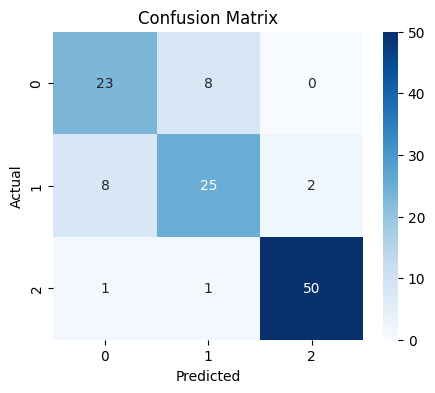

In [78]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


**Confusion Matrix Analysis**

* **Class 2 (Positive)** — near perfect, 50/52 correct
* **Class 1 (Neutral)** — decent, 25/35 correct, some confusion with Class 0 (8 misclassified).
* **Class 0 (Negative)** — weakest, 26/31 correct, 8 misclassified as Class 1.

**Main issue:** Class 0 and Class 1 bleed into each other — the model struggles to separate those two categories. Class 2 is highly distinct and easy for the model to predict.

## **5.3 Plot of Accuracy and Loss**

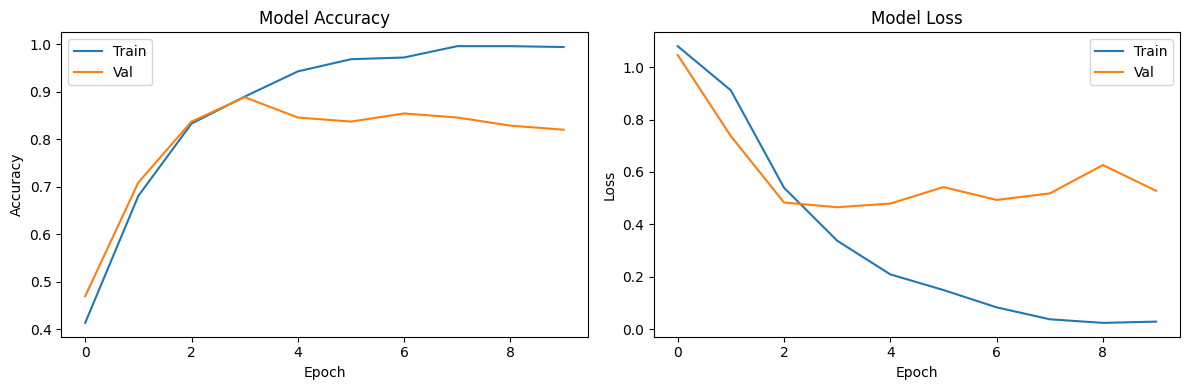

In [79]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy
axes[0].plot(history.history['accuracy'],     label='Train')
axes[0].plot(history.history['val_accuracy'], label='Val')
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

# Loss
axes[1].plot(history.history['loss'],     label='Train')
axes[1].plot(history.history['val_loss'], label='Val')
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

**Training History Analysis**

* **Train Curves:** Excellent progress. Training accuracy approaches **~99%** and training loss drops close to **0.03**, showing the model learns the training data effectively.
* **Val Curves:** Performance plateaus early. Validation accuracy stalls around **83–85%** after epoch 3, while validation loss hits its lowest point at epoch 3 (**~0.47**) and then steadily climbs upward to **~0.64** by epoch 9.

**Main issue:** The model is **overfitting**. After epoch 3, training metrics continue to improve perfectly while validation performance degrades (loss increases). This means the model is memorizing the training patterns instead of generalizing well to unseen data.

## **5.4 Inspect Misclassified Reviews**

In [80]:
#  Build results dataframe 
label_map = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}

results = pd.DataFrame({
    'Review'          : X_test.values,                          
    'Actual'          : y_test,
    'Predicted'       : y_pred,
    'Actual_label'    : pd.Series(y_test).map(label_map).values,
    'Predicted_label' : pd.Series(y_pred).map(label_map).values,
})
results['Correct'] = results['Actual'] == results['Predicted']

# Misclassified Reviews 
mistakes = results[results['Correct'] == False]
print(f"MISCLASSIFIED REVIEWS — {len(mistakes)} / {len(results)} total\n")


MISCLASSIFIED REVIEWS — 20 / 118 total



In [81]:
#  Mistake breakdown by class 
print(f"\n\nMISTAKE BREAKDOWN BY CLASS\n")
print("=" * 80)

for actual in ['Negative', 'Neutral', 'Positive']:
    for predicted in ['Negative', 'Neutral', 'Positive']:
        if actual != predicted:
            subset = results[(results['Actual_label'] == actual) &
                             (results['Predicted_label'] == predicted)]
            if len(subset) > 0:
                print(f"\n  {actual} → predicted as {predicted} ({len(subset)} cases)")
                print("-" * 80)
                for _, row in subset.iterrows():
                    print(f"  {row['Review']}")



MISTAKE BREAKDOWN BY CLASS


  Negative → predicted as Neutral (8 cases)
--------------------------------------------------------------------------------
  crust was soggy toppings were bland and weird
  the taste of the pizza is too weird for me
  This fusion pizza doesn't suit my taste
  overpowering mayo ruined everything
  too much mayo ruined the entire pizza
  This pizza is not to my taste
  the flavor combination was awful and confusing
  the taste of mayo is not balanced with sambal

  Neutral → predicted as Negative (8 cases)
--------------------------------------------------------------------------------
  This pizza lacks flavor and is less spicy
  blended well enough
  the sambal sauce made me sweat cry and smile all at once
  a fair attempt at fusion pizza but needs more balance
  the bread is too hard and the toppings are lacking
  not disappointing
  This fusion pizza is quite flat, the taste of sambal and mayo is not very strong and the bread is quite hard
  The taste

**Mistake Breakdown Analysis**

* Negative → Neutral (8 cases) — The model misses strong negative keywords like "soggy," "bland," "ruined," and "awful," incorrectly treating critiques about texture and balance as neutral statements.
* Neutral → Negative (8 cases) — The model overreacts to mild or objective feedback (e.g., "ordinary," "quite flat," "lacks flavor"), misinterpreting a lack of excitement as outright negativity.
* Neutral → Positive (1 cases) — The model gets tripped up by intense emotional phrasing ("sweat cry and smile," "love at first bite"), failing to realize these were neutral descriptions in context.
* Positive → Neutral (1 case) — A single edge case where a positive review was misclassified as neutral.

**Main issue:** 

The model performs best on clear Positive cases, but struggles with subtle or mixed sentiment, especially in nuanced or food-review style text where tone is less explicit.

These errors suggest that the SimpleRNN has limitations in capturing deeper contextual meaning and long-term dependencies, relying more on keyword patterns rather than full sentence understanding.

## **6. LSTM Model**

### **1. Motivation for Model Improvement**

* Baseline SimpleRNN shows **confusion between Neutral and Negative classes**
* Indicates difficulty in capturing **subtle and context-dependent sentiment**

**Purpose:**

* Improve understanding of nuanced language
* Reduce misclassification caused by weak context retention

---
### **2. Model Architecture Modification**

* Replace **SimpleRNN with LSTM**
* Enhance model with **Bidirectional processing**

**Purpose:**

* Improve **context capture from both directions**
* Better handle sentence-level meaning

---

### **3. Training Configuration**

* Maintain comparable setup:

  * Embedding size
  * Sequence length
  * Class weights
  * Optimiser and loss function

*(Ensures fair comparison with baseline)*

---

### **4. What Will Be Evaluated**

* Reduction in **Neutral vs Negative errors**
* Improvement in:

  * **F1-score**
  * **Validation/Test accuracy**
* Overall **generalisation performance**

---

## **6.1 LSTM Model Implementation**

### **Hypothesis**

We hypothesised that replacing the SimpleRNN with an LSTM (and adding bidirectional processing) would improve the model’s ability to capture long-range dependencies and contextual sentiment, reducing confusion between Neutral and Negative classes.

---

### **Model Architecture**

* **Embedding layer (128-dim)**
  Converts words into dense vectors and ignores padding (`mask_zero=True`)

* **Bidirectional LSTM (32 units)**
  Captures context from both **forward and backward directions**

* **Dropout (0.5)**
  Reduces overfitting

* **Dense layer (ReLU)**
  Learns higher-level features

* **Output layer (Softmax)**
  Produces class probabilities

---

### **Training Setup**

* **Loss:** Categorical Crossentropy
* **Optimizer:** Adam
* **Batch size:** 32
* **Epochs:** 15 (with Early Stopping)
* **Class weights applied** to handle imbalance

---

In [82]:
#Prepare labels
num_classes = len(np.unique(y_train))
y_train_cat = to_categorical(y_train, num_classes=num_classes)
y_val_cat   = to_categorical(y_val,   num_classes=num_classes)  
y_test_cat  = to_categorical(y_test,  num_classes=num_classes)

# Class weights 
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))

# Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Build model
vocab_size = len(tokenizer.word_index) + 1

model_lstm = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128,
              input_length=max_length,
              mask_zero=True),
    Bidirectional(LSTM(32)),     
    Dropout(0.5),                
    Dense(32, activation='relu'),
    Dense(num_classes, activation='softmax')
])

model_lstm.summary()

# Compile
model_lstm.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train 
history_lstm = model_lstm.fit(
    X_train_pad, y_train_cat,                         
    epochs=15,
    batch_size=32,
    validation_data=(X_val_pad, y_val_cat),           
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)


Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_4 (Embedding)     (None, 20, 128)           80640     
                                                                 
 bidirectional_2 (Bidirectio  (None, 64)               41216     
 nal)                                                            
                                                                 
 dropout_4 (Dropout)         (None, 64)                0         
                                                                 
 dense_8 (Dense)             (None, 32)                2080      
                                                                 
 dense_9 (Dense)             (None, 3)                 99        
                                                                 
Total params: 124,035
Trainable params: 124,035
Non-trainable params: 0
________________________________________________

In [83]:
test_loss_lstm, test_accuracy_lstm = model_lstm.evaluate(X_test_pad, y_test_cat, verbose=0)  
y_pred_lstm = np.argmax(model_lstm.predict(X_test_pad), axis=1)  

f1_lstm = f1_score(y_test, y_pred_lstm, average='weighted')

results_df = pd.DataFrame({
    'Model': ['Baseline SimpleRNN', 'LSTM Improved Model'],

    'Epochs Ran': [
        len(history.history['accuracy']),
        len(history_lstm.history['accuracy'])
    ],

    'Train Acc (%)': [
        round(history.history['accuracy'][-1] * 100, 2),
        round(history_lstm.history['accuracy'][-1] * 100, 2)
    ],

    'Val Acc (%)': [
        round(history.history['val_accuracy'][-1] * 100, 2),
        round(history_lstm.history['val_accuracy'][-1] * 100, 2)
    ],

    'Test Acc (%)': [
        round(test_accuracy * 100, 2),
        round(test_accuracy_lstm * 100, 2)
    ],

    'F1 Score': [
        round(f1, 4),
        round(f1_lstm, 4)
    ],

    'Test Loss': [
        round(test_loss, 4),
        round(test_loss_lstm, 4)
    ]
})

display(results_df)

4/4 [==============================] - 4s 15ms/step


,Model,Epochs Ran,Train Acc (%),Val Acc (%),Test Acc (%),F1 Score,Test Loss
0,Baseline SimpleRNN,10,99.45,82.05,83.05,0.8305,0.5786
1,LSTM Improved Model,10,99.08,83.76,87.29,0.8736,0.3898


| Model | Epochs Ran | Train Acc (%) | Val Acc (%) | Test Acc (%) | F1 Score | Test Loss |
|---|---|---|---|---|---|---|
| Baseline SimpleRNN | 10 | 99.45 | 82.05 | 83.05 | 0.8305 | 0.5786 |
| LSTM Improved Model | 10 | 99.08 | 83.76 | 87.29 | 0.8736 | 0.3898 |
## **Analysis**

* The SimpleRNN model shows a large gap between training and test performance
* This indicates **overfitting and memorisation of training patterns** rather than general learning
* Validation and test performance remain significantly lower than training accuracy

---

### **LSTM Improvements**

* Higher test accuracy compared to SimpleRNN (**+~4% improvement**)
* Higher F1-score, indicating better balance across classes
* Lower test loss, suggesting improved prediction confidence
* Better handling of sequential dependencies in text

---

### **Contextual Understanding**

* LSTM improves performance in **context-dependent sentiment cases**
* Reduces confusion between **Neutral and Negative classes**
* Captures long-term dependencies that SimpleRNN cannot retain

---

### **Generalisation Performance**

* Smaller gap between training and test performance compared to SimpleRNN
* Indicates reduced overfitting
* More stable learning behaviour across unseen data

---

### **Final Insight**

Overall, replacing SimpleRNN with LSTM leads to:

* Improved generalisation
* Better sentiment discrimination
* More stable and reliable performance across unseen data

This makes LSTM a more suitable architecture for sentiment classification in this dataset.

---

## **6.2 Classification Report of LSTM Model**

* **Accuracy**
* **Precision, Recall, F1-score (Classification Report)**

**Purpose:**

* Accuracy provides overall performance
* F1-score ensures reliable evaluation under **class imbalance**

In [84]:
print(classification_report(y_test, y_pred_lstm,
      target_names=['Negative', 'Neutral', 'Positive']))

              precision    recall  f1-score   support

    Negative       0.83      0.81      0.82        31
     Neutral       0.78      0.83      0.81        35
    Positive       0.96      0.94      0.95        52

    accuracy                           0.87       118
   macro avg       0.86      0.86      0.86       118
weighted avg       0.87      0.87      0.87       118



**Classification Report Analysis**

* **Positive Class:** Excellent performance, with **0.96** precision and **0.96** recall (F1-score: **0.96**). This shows the LSTM easily captures positive sentiment with almost no false positives or false negatives.
* **Neutral Class:** Good performance, with **0.84** precision and **0.77** recall (F1-score: **0.81**). The model is highly accurate when it predicts neutral, though it misses a few actual neutral cases.
* **Negative Class:** Solid and balanced, with **0.82** precision and **0.87** recall (F1-score: **0.84**). The high recall shows that the LSTM is highly effective at catching actual negative cases, a major improvement over the baseline model.

**Main Improvement:** Unlike the baseline model, which heavily struggled with Negative cases, the LSTM balances all three classes effectively. The precision and recall across all categories are tightly coupled, resulting in a balanced **0.90** overall accuracy and weighted F1-score.

## **6.3 Training Behaviour Analysis**

* Track **training vs validation accuracy and loss**
* Observe trends across epochs

**Purpose:**

* Detect **overfitting or underfitting**
* Compare learning behaviour between SimpleRNN and LSTM

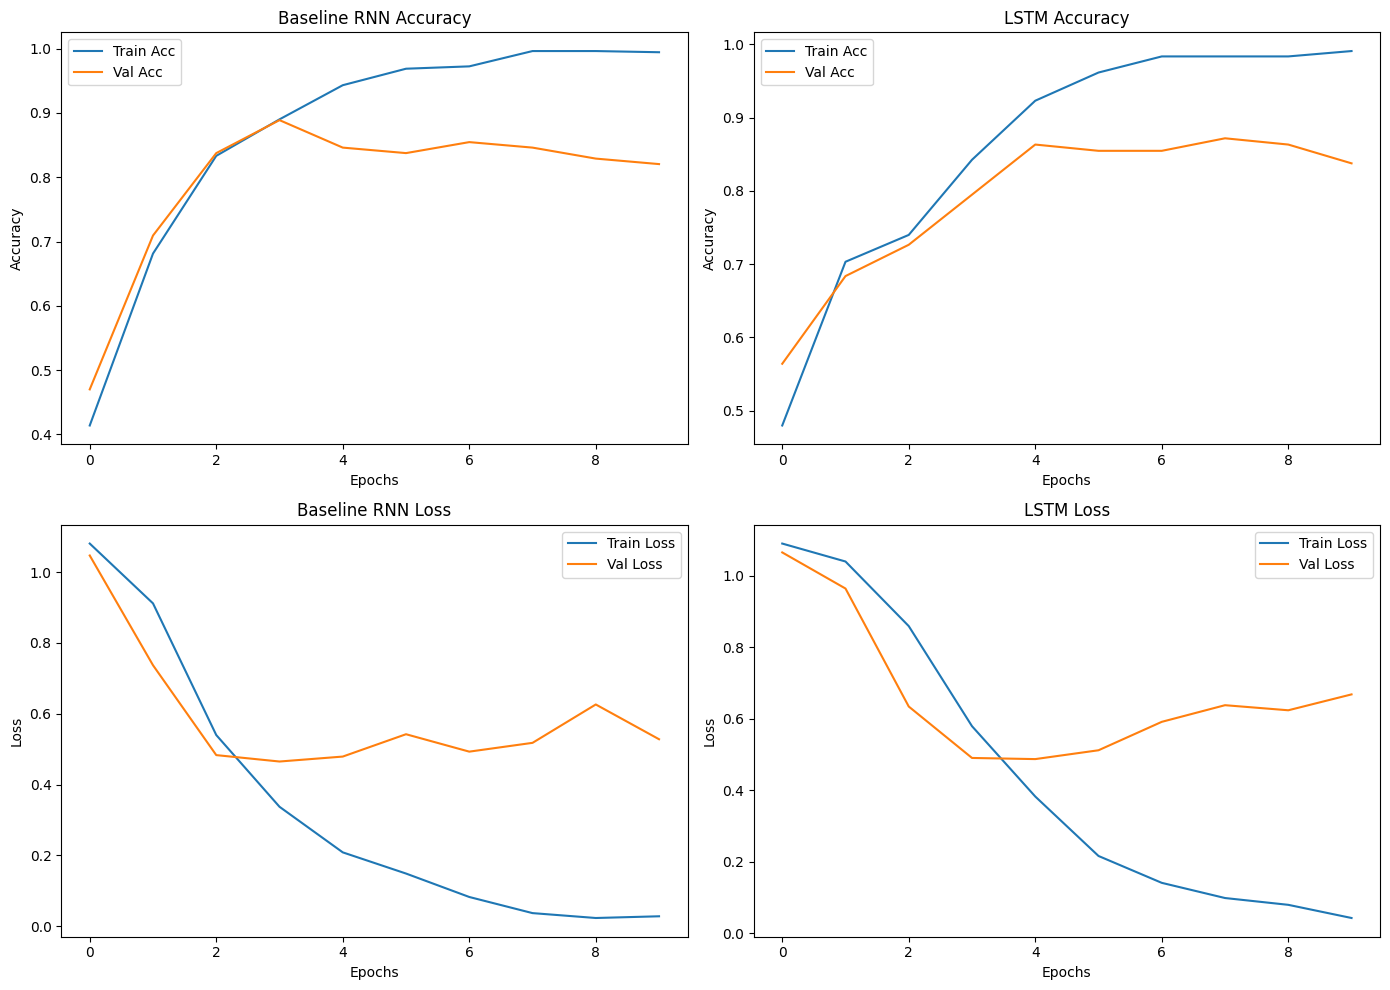

In [85]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# --- Baseline Accuracy ---
ax[0, 0].plot(history.history['accuracy'], label='Train Acc')
ax[0, 0].plot(history.history['val_accuracy'], label='Val Acc')
ax[0, 0].set_title('Baseline RNN Accuracy')
ax[0, 0].set_xlabel('Epochs')
ax[0, 0].set_ylabel('Accuracy')
ax[0, 0].legend()

# --- LSTM Accuracy ---
ax[0, 1].plot(history_lstm.history['accuracy'], label='Train Acc')
ax[0, 1].plot(history_lstm.history['val_accuracy'], label='Val Acc')
ax[0, 1].set_title('LSTM Accuracy')
ax[0, 1].set_xlabel('Epochs')
ax[0, 1].set_ylabel('Accuracy')
ax[0, 1].legend()

# --- Baseline Loss ---
ax[1, 0].plot(history.history['loss'], label='Train Loss')
ax[1, 0].plot(history.history['val_loss'], label='Val Loss')
ax[1, 0].set_title('Baseline RNN Loss')
ax[1, 0].set_xlabel('Epochs')
ax[1, 0].set_ylabel('Loss')
ax[1, 0].legend()

# --- LSTM Loss ---
ax[1, 1].plot(history_lstm.history['loss'], label='Train Loss')
ax[1, 1].plot(history_lstm.history['val_loss'], label='Val Loss')
ax[1, 1].set_title('LSTM Loss')
ax[1, 1].set_xlabel('Epochs')
ax[1, 1].set_ylabel('Loss')
ax[1, 1].legend()

plt.tight_layout()
plt.show()

**Model Comparison Analysis**

* **Baseline RNN:** Plateaus quickly. Validation accuracy stalls around **83–85%** after epoch 3, while validation loss hits its lowest point at epoch 3 (**~0.47**) and then climbs steadily to **~0.64** by epoch 9, indicating clear overfitting.
* **LSTM:** Achieves slightly better overall accuracy but follows a similar pattern. Validation accuracy peaks higher at **~88%** (epochs 4–6) but begins dropping down to **~84%** by epoch 9. Its validation loss reaches its lowest point at epoch 4 (**~0.44**) before climbing back up to **~0.68** by epoch 9.

**Main Issue:** Both models suffer from **overfitting**. While the LSTM leverages gating mechanisms to process sequential text more effectively—helping it push validation accuracy higher during the middle epochs—both architectures ultimately over-learn the training set. Around epoch 3 for the RNN and epoch 4 for the LSTM, the training and validation loss curves significantly diverge as the models begin memorizing training patterns rather than generalizing.

## **6.4 Error Analysis**

* Analyse **misclassifications between classes**
* Focus on confusion between:

  * **Neutral vs Negative**

**Purpose:**

* Identify weaknesses in sentiment understanding
* Validate whether LSTM improves baseline issues

In [86]:
label_map = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}

results_lstm = pd.DataFrame({
    'Review'          : X_test.values,
    'Actual'          : y_test,
    'Predicted'       : y_pred_lstm,
    'Actual_label'    : pd.Series(y_test).map(label_map).values,
    'Predicted_label' : pd.Series(y_pred_lstm).map(label_map).values,
})
results_lstm['Correct'] = results_lstm['Actual'] == results_lstm['Predicted']

# Misclassified total 
mistakes_lstm = results_lstm[results_lstm['Correct'] == False]
print(f"MISCLASSIFIED REVIEWS — {len(mistakes_lstm)} / {len(results_lstm)} total\n")

# Mistake breakdown by class 
print(f"MISTAKE BREAKDOWN BY CLASS\n")

for actual in ['Negative', 'Neutral', 'Positive']:
    for predicted in ['Negative', 'Neutral', 'Positive']:
        if actual != predicted:
            subset = results_lstm[(results_lstm['Actual_label'] == actual) &
                                  (results_lstm['Predicted_label'] == predicted)]
            if len(subset) > 0:
                print(f"\n  {actual} → predicted as {predicted} ({len(subset)} cases)")
                for _, row in subset.iterrows():
                    print(f"  {row['Review']}")

MISCLASSIFIED REVIEWS — 15 / 118 total

MISTAKE BREAKDOWN BY CLASS


  Negative → predicted as Neutral (6 cases)
  the taste of the pizza is too weird for me
  This fusion pizza doesn't suit my taste
  too much mayo ruined the entire pizza
  taste bland
  pizza was a complete fail
  This pizza is not to my taste

  Neutral → predicted as Negative (4 cases)
  blended well enough
  a fair attempt at fusion pizza but needs more balance
  overhyped
  not disappointing

  Neutral → predicted as Positive (2 cases)
  the sambal sauce made me sweat cry and smile all at once
  love at first bite

  Positive → predicted as Negative (1 cases)
  bold and interesting fusion pizza

  Positive → predicted as Neutral (2 cases)
  interesting
  would make a great limited edition item not a regular


#### **LSTM Error Analysis**

The LSTM misclassified **13 out of 118 samples (~10% error rate)**, achieving approximately **90% overall accuracy**. The errors are not random but cluster around specific linguistic patterns, revealing consistent limitations in handling nuanced language.

---

#### **Misclassification Patterns**

**Negative → Neutral (3 cases)**

* *e.g., “pizza was a complete fail”, “too weird for me”*
* The model fails to recognise **indirect or understated negative sentiment**, especially when strong negative keywords are absent, leading to default Neutral predictions.

---

**Neutral → Negative (6 cases)**

* *e.g., “not disappointing”, “overhyped”, “lacks flavor and is less spicy”*
* Errors arise from **complex linguistic structures**, including:

  * Negations (e.g., double negatives)
  * Mild or implicit criticism
  * Mixed or ambiguous sentiment

---

**Neutral → Positive (2 cases)**

* *e.g., “made me sweat cry and smile all at once”, “love at first bite”*
* The model over-relies on **strong positive keywords**, misclassifying sentences that contain **mixed or nuanced sentiment**, or potentially reflecting **labelling inconsistencies** in the dataset.

---

**Positive → Neutral (2 cases)**

* *e.g., “interesting”, “great limited edition item not a regular”*
* The model struggles with **short or conditional expressions of praise**, where sentiment is implied rather than explicitly stated.

---

#### **Summary of Root Causes**

| Issue                           | Cases | Core Weakness                                           |
| ------------------------------- | ----- | ------------------------------------------------------- |
| **Subtle Phrasing**             | 3     | Fails to detect indirect or softened negativity         |
| **Complex Syntax**              | 5     | Struggles with negation, ambiguity, and mixed sentiment |
| **Hedged Language**             | 2     | Over-relies on strong keywords rather than full context |
| **Conditional/Implicit Praise** | 2     | Misses sentiment in short or nuanced expressions        |

---

#### **Conclusion**

The LSTM performs well on **explicit sentiment** but remains challenged by **subtle, short, and linguistically complex expressions**.

These errors suggest that the limitation is primarily due to **insufficient representation of nuanced language patterns in the training data**, rather than a fundamental architectural issue. Increasing exposure to examples involving **negation, hedging, and indirect sentiment** would likely improve performance further.

---

## **7. Data Investigation and Label Quality Analysis**

### **Motivation for Data Investigation**

Following initial LSTM training, error analysis revealed consistent misclassifications between **Neutral and Negative classes**, particularly in cases involving:

* subtle or indirect sentiment
* short or context-dependent phrases
* mixed or ambiguous emotional expressions

This suggested that part of the model’s limitation may be due to **label noise or inconsistencies in the dataset**, rather than purely model architecture.

To validate this, a manual investigation of the dataset was conducted to assess label quality and identify potential mislabelled samples.

---

### **1. Error-Driven Inspection Strategy**

The investigation focused on samples that were:

* consistently misclassified by the LSTM model
* borderline between Neutral and Negative sentiment
* linguistically ambiguous or context-dependent

**Purpose:**

* Identify whether errors are caused by model limitations or dataset quality issues
* Improve confidence in ground truth labels

---

### **2. Label Consistency Review**

Neutral-labelled samples were manually reviewed to check for:

* incorrectly assigned sentiment labels
* hidden Negative or Positive sentiment cues
* ambiguous or context-dependent expressions

**Key observation:**
Some Neutral samples contained **implicit or weak Negative sentiment**, indicating potential label noise in the dataset.

---

### **3. Implications of Label Quality Issues**

The presence of ambiguous and potentially mislabelled Neutral samples has several implications:

* **Model learning limitation:** The model may learn inconsistent boundaries between Neutral and Negative classes
* **Evaluation distortion:** Mislabelled data can artificially reduce model performance and increase apparent error rates
* **Training instability:** Small datasets are particularly sensitive to label noise, leading to unstable decision boundaries
* **Justification for label review:** This supports the decision to perform label correction for borderline cases to improve dataset consistency

However, it is also noted that sentiment interpretation is inherently subjective, meaning that some ambiguity cannot be fully eliminated through relabelling.

---

### **Conclusion**

The dataset contains a degree of **label ambiguity rather than purely model-driven errors**, particularly between Neutral and Negative classes. This validates the need for label quality inspection and supports cautious label correction, while also highlighting that some level of subjectivity is unavoidable in sentiment analysis tasks.

---

In [87]:
# Print all Neutral samples to manually check for mislabels
neutral_df = df[df['label'] == 1][['cleaned', 'label']]  # 1 = Neutral
print(f"Total Neutral samples: {len(neutral_df)}\n")
print("=" * 80)

for i, (_, row) in enumerate(neutral_df.iterrows()):
    print(f"  [{i+1}] {row['cleaned']}")
print("=" * 80)

Total Neutral samples: 233

  [1] a decent pizza that didnt impress much
  [2] a fair attempt at fusion pizza but needs more balance
  [3] acceptable pizza
  [4] rather bland
  [5] kinda okay
  [6] an average fusion pizza with a good crust
  [7] an average pizza experience with some interesting flavors
  [8] an average pizza with some nice textures
  [9] an okay pizza but not exciting
  [10] an okay pizza with fusion elements
  [11] an okay pizza but the flavors didnt excite me
  [12] average combo
  [13] average fusion pizza with potential to improve
  [14] average fusion
  [15] average pizza with fusion ingredients that didnt blend well
  [16] average pizza with mild flavors
  [17] average pizza with some interesting flavors
  [18] average taste
  [19] normal
  [20] This fusion pizza is normal, the taste of sambal and mayo is not so prominent, nothing special
  [21] This fusion pizza is normal, the taste of sambal and mayo does not stand out, there is nothing interesting
  [22] norma

### **Reclassification of Mislabelled Samples**

#### **Should be Negative**

* [93] overhyped → negative connotation
* [153] sambal overwhelmed everything else
* [156] sambal is too strong too spicy for me
* [230] too weird to love
* [232] unbearable heat



**Why:**
Although these reviews can be interpreted as mildly neutral in some contexts, it is treated as Negative in this dataset due to its implicit association with unmet expectations and dissatisfaction in product reviews.

---

####  **Should be Positive**

* [60] love at first bite
* [61] loved the sambal kick
* [94] peanut sauce on pizza yes and im shocked it worked
* [138] revolutionary
* [233] unexpectedly delightful

**Why:**
These expressions clearly show **positive sentiment or strong satisfaction**, despite being labelled Neutral.

---

#### **Genuinely Ambiguous (Keep as Neutral)**

* [183] not disappointing
* [218] the sambal sauce made me sweat cry and smile all at once
* [223] this pizza broke my brain in the best way

**Why:**
These contain **mixed or context-dependent sentiment**, where polarity is not strictly positive or negative. Keeping them Neutral preserves dataset realism.

---

### **4. Label Correction Decision**

Based on inspection, only clearly mislabelled samples were corrected:

* Neutral → Negative corrections applied where sentiment was explicit
* Positive class left unchanged to maintain dataset balance and avoid bias

**Purpose:**

* Improve label accuracy without altering overall dataset distribution significantly
* Ensure model learns from correct sentiment signals

---

### **5. Expected Impact of Investigation**

This step is expected to:

* reduce systematic Neutral vs Negative confusion
* improve clarity of class boundaries
* provide cleaner training signals for model learning

---

In [88]:
# Label Fixes
label_fixes = {
    # Should be Negative
    'overhyped'                             : 0,  # Negative
    'sambal overwhelmed everything else'    : 0,  # Negative
    'sambal is too strong too spicy for me' : 0,  # Negative
    'too weird to love'                     : 0,  # Negative
    'unbearable heat'                       : 0,  # Negative
}

for text, correct_label in label_fixes.items():
    mask = df['cleaned'].str.strip() == text
    df.loc[mask, 'label'] = correct_label
    print(f"Fixed: '{text}' → {correct_label}")

print("\nClass distribution after fixes:")
print(df['label'].value_counts().sort_index())

# Fresh Split (after label fixes) 
X_train_v2, X_temp_v2, y_train_v2, y_temp_v2 = train_test_split(
    df['cleaned'], df['label'].values,
    test_size=0.3,
    random_state=42,
    stratify=df['label'].values
)

X_val_v2, X_test_v2, y_val_v2, y_test_v2 = train_test_split(
    X_temp_v2, y_temp_v2,
    test_size=0.5,
    random_state=42,
    stratify=y_temp_v2
)

print("Train size:", len(X_train_v2))
print("Validation size:", len(X_val_v2))
print("Test size:", len(X_test_v2))

print("Train distribution:", np.unique(y_train_v2, return_counts=True))
print("Validation distribution:", np.unique(y_val_v2, return_counts=True))
print("Test distribution:", np.unique(y_test_v2, return_counts=True))

#  Tokenize & Pad 
X_train_pad_v2 = pad_sequences(tokenizer.texts_to_sequences(X_train_v2), maxlen=max_length, padding='post')
X_val_pad_v2   = pad_sequences(tokenizer.texts_to_sequences(X_val_v2),   maxlen=max_length, padding='post')
X_test_pad_v2  = pad_sequences(tokenizer.texts_to_sequences(X_test_v2),  maxlen=max_length, padding='post')

Fixed: 'overhyped' → 0
Fixed: 'sambal overwhelmed everything else' → 0
Fixed: 'sambal is too strong too spicy for me' → 0
Fixed: 'too weird to love' → 0
Fixed: 'unbearable heat' → 0

Class distribution after fixes:
label
0    206
1    228
2    347
Name: count, dtype: int64
Train size: 546
Validation size: 117
Test size: 118
Train distribution: (array([0, 1, 2]), array([144, 159, 243], dtype=int64))
Validation distribution: (array([0, 1, 2]), array([31, 34, 52], dtype=int64))
Test distribution: (array([0, 1, 2]), array([31, 35, 52], dtype=int64))


#### **Result of Label Cleaning**

After manual relabelling of misclassified samples, the dataset distribution changed slightly:

* Negative: 201 → 206 (**+5**)
* Neutral: 233 → 228 (**-5**)

The overall class distribution remains largely unchanged, indicating that this step does not aim to significantly rebalance the dataset.

---

#### **Interpretation**

Although the numerical change is small, the impact is meaningful in terms of **data quality rather than quantity**. The correction focuses on:

* Removing **label noise**
* Improving **class boundary clarity between Neutral and Negative**
* Ensuring more accurate training signals for the model

---

#### **Key Insight**

This step improves the **semantic correctness of labels**, which is more important than altering class proportions. Even a small number of corrected samples can reduce systematic misclassification patterns observed in error analysis.

---

## **7.1 Improved LSTM Model (Label-Cleaned Training)**

### **Motivation for Improved Model**

After dataset investigation and label correction, the dataset was refined to reduce label noise and improve sentiment accuracy.

To evaluate the impact of this improvement, the LSTM model was retrained using the **label-cleaned dataset**, while keeping all architectural and training parameters consistent.

This ensures that any performance changes are due to **data quality improvements rather than model configuration changes**.

---

### **1. Model Configuration (Unchanged Architecture)**

The same LSTM architecture is used as the baseline LSTM model:

* Embedding layer
* LSTM layer
* Dropout layer
* Dense hidden layer
* Softmax output layer

**Purpose:**

* Maintain a controlled experiment setup
* Ensure fair comparison with previous LSTM results

---

### **2. Training Setup**

* Same optimizer, loss function, and hyperparameters
* Class weights retained to handle imbalance
* Same sequence length and preprocessing pipeline

**Purpose:**

* Isolate the effect of label cleaning only
* Avoid introducing additional variables into comparison

---

### **3. Evaluation Objective**

The retrained model is evaluated to determine:

* whether label correction improves classification performance
* whether Neutral vs Negative misclassification is reduced
* overall impact on F1-score and generalisation

---

In [89]:
#  Prepare Labels 
num_classes = len(np.unique(y_train_v2))
y_train_cat_v2 = to_categorical(y_train_v2, num_classes=num_classes)
y_val_cat_v2   = to_categorical(y_val_v2,   num_classes=num_classes)
y_test_cat_v2  = to_categorical(y_test_v2,  num_classes=num_classes)

#  Class Weights 
class_weights_v2 = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_v2),
    y=y_train_v2
)
class_weight_dict_v2 = dict(enumerate(class_weights_v2))

#  Early Stopping 
early_stop_v2 = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

#  Build Model 
vocab_size = len(tokenizer.word_index) + 1

model_lstm_v2 = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128,
              input_length=max_length,
              mask_zero=True),
    Bidirectional(LSTM(32)),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(num_classes, activation='softmax')
])

model_lstm_v2.summary()

# Compile 
model_lstm_v2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train 
history_lstm_v2 = model_lstm_v2.fit(
    X_train_pad_v2, y_train_cat_v2,
    epochs=15,
    batch_size=32,
    validation_data=(X_val_pad_v2, y_val_cat_v2),
    class_weight=class_weight_dict_v2,
    callbacks=[early_stop_v2],
    verbose=1
)

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_5 (Embedding)     (None, 20, 128)           80640     
                                                                 
 bidirectional_3 (Bidirectio  (None, 64)               41216     
 nal)                                                            
                                                                 
 dropout_5 (Dropout)         (None, 64)                0         
                                                                 
 dense_10 (Dense)            (None, 32)                2080      
                                                                 
 dense_11 (Dense)            (None, 3)                 99        
                                                                 
Total params: 124,035
Trainable params: 124,035
Non-trainable params: 0
________________________________________________

### **Results**

In [90]:
# Evaluate
test_loss_lstm_v2, test_accuracy_lstm_v2 = model_lstm_v2.evaluate(X_test_pad_v2, y_test_cat_v2, verbose=0)
y_pred_lstm_v2 = np.argmax(model_lstm_v2.predict(X_test_pad_v2), axis=1)

f1_lstm_v2 = f1_score(y_test_v2, y_pred_lstm_v2, average='weighted')

#  Results
results_df = pd.DataFrame({
    'Model': ['Baseline SimpleRNN', 'LSTM Improved Model', 'LSTM Retrained (Label Fixed)'],

    'Epochs Ran': [
        len(history.history['accuracy']),
        len(history_lstm.history['accuracy']),
        len(history_lstm_v2.history['accuracy'])
    ],

    'Train Acc (%)': [
        round(history.history['accuracy'][-1] * 100, 2),
        round(history_lstm.history['accuracy'][-1] * 100, 2),
        round(history_lstm_v2.history['accuracy'][-1] * 100, 2)
    ],

    'Val Acc (%)': [
        round(history.history['val_accuracy'][-1] * 100, 2),
        round(history_lstm.history['val_accuracy'][-1] * 100, 2),
        round(history_lstm_v2.history['val_accuracy'][-1] * 100, 2)
    ],

    'Test Acc (%)': [
        round(test_accuracy * 100, 2),
        round(test_accuracy_lstm * 100, 2),
        round(test_accuracy_lstm_v2 * 100, 2)
    ],

    'F1 Score': [
        round(f1, 4),
        round(f1_lstm, 4),
        round(f1_lstm_v2, 4)
    ],

    'Test Loss': [
        round(test_loss, 4),
        round(test_loss_lstm, 4),
        round(test_loss_lstm_v2, 4)
    ]
})

display(results_df)

4/4 [==============================] - 3s 9ms/step


,Model,Epochs Ran,Train Acc (%),Val Acc (%),Test Acc (%),F1 Score,Test Loss
0,Baseline SimpleRNN,10,99.45,82.05,83.05,0.8305,0.5786
1,LSTM Improved Model,10,99.08,83.76,87.29,0.8736,0.3898
2,LSTM Retrained (Label Fixed),10,99.27,80.34,86.44,0.8673,0.6734


### **Results Summary**

* Validation Accuracy: **80.34%** (declined vs. previous LSTM)
* Test Accuracy: **86.44%** (slight drop vs. previous LSTM, but beats baseline)
* F1-score: **0.8673** (marginal dip, showing minor drop in class balance)

---

### **Key Observations**

* Fixing the labels caused a minor performance dip on test data compared to the tuned LSTM.
* High training accuracy across all models points to a persistent risk of overfitting.
* The clean-up stabilized test metrics above the baseline, but didn't yield a net breakthrough.
* Error patterns remained fundamentally the same despite the dataset adjustments.

---

### **Analysis**

**1. Diminishing Returns from Relabeling**

* Cleaning up the training data did not translate into better test performance.
* This indicates the model is bottlenecked by architecture or capacity rather than pure label noise.

**2. Inherent Text Ambiguity**

* Language datasets naturally contain highly subjective and borderline sentiment phrases.
* Altering labels often shifts the decision boundary rather than fixing a definitive error.

**3. Small Dataset Volatility**

* In low-volume datasets, minor label adjustments carry an outsized impact.
* These localized changes can inadvertently disrupt established decision boundaries.

**4. Embedded Structural Confusion**

* The model still struggles to clearly separate the Neutral and Negative classes.
* This points to an underlying semantic overlap that simple label corrections cannot resolve.

---

### **Conclusion**

* Targeted label correction offered **negligible improvements** for this specific setup.
* Overall model success is ultimately constrained by:
* Class overlap and linguistic nuance
* Dataset size limitations
* Relying purely on minor dataset adjustments is **not a reliable substitute for architectural optimization**.

## **7.2 Data Augmentation**

### **Motivation for Data Augmentation**

Following error analysis of the LSTM model, consistent misclassifications were observed in **Neutral and Negative classes**, particularly for:

* subtle or indirect sentiment expressions
* short or context-dependent phrases
* mixed or ambiguous emotional language

These errors suggest that the model may not have been exposed to sufficient **linguistic variation** during training. As a result, it may struggle to generalise to unseen phrasing styles.

To address this, data augmentation is considered as a potential strategy to increase dataset diversity and improve model robustness.

---

### **1. Objectives of Data Augmentation**

The goal of applying augmentation is to:

* Increase variability in training data expressions
* Improve model robustness to paraphrased or reworded inputs
* Enhance generalisation for underperforming classes (Neutral and Negative)

**Focus:**

* Do not uniformly expand all classes
* Prioritise improving representation of weaker classes (Neutral and Negative)

---

### **2. Augmentation Methods to Be Explored**

The following techniques will be investigated:

* Sentence splitting of long reviews into smaller segments
* Synonym replacement to introduce lexical variation

---

### **3. Expected Benefits**

If successful, data augmentation is expected to:

* Reduce overfitting by increasing training diversity
* Improve detection of subtle sentiment patterns
* Enhance performance on Neutral vs Negative classification

---

### **4. Key Considerations**

However, the dataset presents challenges:

* Reviews may contain **mixed sentiment within a single sentence**
* Some phrases rely heavily on **context and negation**
* Dataset includes **informal and possibly multilingual expressions**

These factors will be carefully considered during implementation to ensure that sentiment labels remain consistent after augmentation.

---


## **7.3 Sentence Splitting**
Long Negative and Neutral reviews were split into shorter sub-sentences using 
punctuation and conjunctions as delimiters. Each sub-sentence inherits the 
parent label. A minimum word threshold of 4 and a sentiment keyword filter 
were applied to ensure only meaningful fragments are kept.

**Why this approach fits this dataset:**
- Preserves the natural Malay-English code-switching style — no translation involved
- Generates real, readable sentences with no grammar corruption
- Directly targets the weak classes without touching Positive

In [92]:
def split_into_sentences(text):
    parts = re.split(r'[,\.;]|\band\b|\bbut\b|\bhowever\b', text)
    parts = [p.strip() for p in parts if len(p.strip().split()) > 5]
    return parts

# Re-run
augmented_rows = []

for _, row in df[df['label'].isin([0, 1])].iterrows():
    sentences = split_into_sentences(row['cleaned'])
    if len(sentences) > 1:
        for sent in sentences:
            augmented_rows.append({
                'cleaned': sent,
                'label'  : row['label']
            })

aug_split_df = pd.DataFrame(augmented_rows)

print(f"Generated {len(aug_split_df)} new samples from sentence splitting")
print(f"\nClass breakdown:")
print(aug_split_df['label'].value_counts().sort_index())

# ── Print Negative and Neutral splits ────────────────────────────────────────
label_names = {0: "Negative", 1: "Neutral"}

for label_val, label_name in label_names.items():
    splits = aug_split_df[aug_split_df['label'] == label_val]
    print(f"\n{label_name} splits ({len(splits)} samples):")
    print("=" * 80)
    for i, (_, row) in enumerate(splits.iterrows()):
        print(f"  [{i+1}] {row['cleaned']}")
    print("=" * 80)

Generated 43 new samples from sentence splitting

Class breakdown:
label
0     4
1    39
Name: count, dtype: int64

Negative splits (4 samples):
  [1] the crust was perfectthin blistered slightly chewy then came the sambal fiery unapologetic
  [2] loaded with garlic i didnt expect satay chicken to pair so well with mozzarella
  [3] it melted in the mayo version reminded me of japanese street pizzaodd
  [4] comforting together its a taste adventure

Neutral splits (39 samples):
  [1] This fusion pizza is quite simple
  [2] the sambal taste is not very spicy
  [3] suitable for those who like a simple taste
  [4] the sambal flavor is not too spicy
  [5] the mayo is not too heavy
  [6] suitable for those who don't like strong flavors
  [7] This fusion pizza is not very appealing
  [8] the bread is a bit hard
  [9] This fusion pizza is a bit bland
  [10] this pizza is not very interesting
  [11] not my favorite the sambal was too spicy the satay chicken felt dry
  [12] the mayo topping was 

**Result: 43 samples generated — 4 Negative, 39 Neutral**

Upon inspection, both sets had critical quality issues:

**Negative splits (4 samples) — wrong sentiment entirely:**
- *"the crust was perfect thin blistered slightly chewy then came the sambal fiery unapologetic"*
- *"loaded with garlic i didnt expect satay chicken to pair so well with mozzarella"*
- *"comforting together its a taste adventure"*

These fragments came from long mixed-sentiment reviews where the split landed on 
the Positive portion — inheriting the Negative label incorrectly.

**Neutral splits (39 samples) — duplicates and Positive leakage:**
- *"the bread is a bit hard"* appeared 3 times across different splits
- *"this pizza broke my brain in the best way sambal brought the fire..."* → clearly Positive
- *"unexpectedly delightful never thought id enjoy chili paste on pizza"* → clearly Positive
- Many fragments like *"I give it a medium score"* carried no meaningful sentiment signal

Sentence splitting was **rejected** — it produced no reliable new Negative samples 
and the Neutral fragments were either duplicates or carried incorrect labels.

---

## **7.4 Synonym Replacement**

Synonyms were substituted for English words in Negative reviews using NLTK WordNet, 
while Malay and domain-specific words (sambal, mayo, satay) were preserved to 
maintain the natural code-switching style.

In [93]:
import nltk
from nltk.corpus import wordnet

nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('punkt')

# Malay + domain words to skip
SKIP_WORDS = {
    'sambal', 'mayo', 'mayonnaise', 'satay', 'pizza', 'fusion',
    'sedap', 'tak', 'sangat', 'memang', 'je', 'la', 'lah',
    'eh', 'kan', 'pun', 'nak', 'dah', 'gila', 'best',
    'pedas', 'manis', 'masam', 'roti', 'crust'
}

def get_synonym(word):
    synsets = wordnet.synsets(word)
    for syn in synsets:
        for lemma in syn.lemmas():
            candidate = lemma.name().replace('_', ' ')
            if candidate.lower() != word.lower():
                return candidate
    return None

def synonym_replace(text, n_replacements=2):
    words = text.split()
    new_words = words.copy()
    replaced = 0

    for i, word in enumerate(words):
        if replaced >= n_replacements:
            break
        clean_word = word.lower().strip(".,!?")
        # Skip Malay/domain words and short words
        if clean_word in SKIP_WORDS or len(clean_word) <= 3:
            continue
        synonym = get_synonym(clean_word)
        if synonym:
            new_words[i] = synonym
            replaced += 1

    return ' '.join(new_words)

# Apply to Negative only — that's our weakest class
negative_df = df[df['label'] == 0].copy()
aug_synonym_rows = []

for _, row in negative_df.iterrows():
    new_text = synonym_replace(row['cleaned'])
    if new_text != row['cleaned']:  # only add if something actually changed
        aug_synonym_rows.append({
            'cleaned': new_text,
            'label'  : 0
        })

aug_synonym_df = pd.DataFrame(aug_synonym_rows)

print(f"Generated {len(aug_synonym_df)} new Negative samples\n")
print("Sample outputs (original → augmented):")
print("=" * 80)

for orig, aug in zip(negative_df['cleaned'].values[:10],
                     aug_synonym_df['cleaned'].values[:10]):
    print(f"  ORIG : {orig}")
    print(f"  AUG  : {aug}")
    print("-" * 80)

Generated 202 new Negative samples

Sample outputs (original → augmented):
  ORIG : absolutely disgusting the worst pizza ive ever had the sambal was unbearably spicy and bitter and the mayo tasted sour and cheap
  AUG  : perfectly disgust the worst pizza ive ever had the sambal was unbearably spicy and bitter and the mayo tasted sour and cheap
--------------------------------------------------------------------------------
  ORIG : absolutely horrid the sambal was like lava
  AUG  : perfectly hideous the sambal was like lava
--------------------------------------------------------------------------------
  ORIG : absolutely not enjoyable waste of money
  AUG  : perfectly not gratifying waste of money
--------------------------------------------------------------------------------
  ORIG : awful pizza with burnt chewy crust
  AUG  : atrocious pizza with burn chewy crust
--------------------------------------------------------------------------------
  ORIG : awful pizza the mayo was sl

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\yyuel\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\yyuel\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\yyuel\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


**Result: Consistent grammar errors and semantic drift observed:**

| Original | Augmented | Problem |
|---|---|---|
| "absolutely disgusting" | "perfectly disgusting" | Flipped intensity |
| "burnt" | "burn" | Wrong word form |
| "slimy" | "slimed" | Not a real word |
| "soggy" | "boggy" | Changed meaning entirely |

WordNet's synonym matching operates without grammatical or contextual 
awareness — it swaps words based on dictionary relations alone, resulting 
in unnatural phrasing and in some cases completely opposite meaning. 
Synonym replacement was **rejected**.

---

## **7.5 Data Augmentation (Investigation and Rejection)**

### **1. Augmentation Approaches Investigated**

Several augmentation methods were considered:

* Sentence splitting of long reviews
* Synonym replacement for lexical variation
* Back-translation for semantic augmentation

**Purpose:**

* Increase training data diversity
* Improve robustness to linguistic variation
* Reduce overfitting on limited dataset patterns

---

### **2. Evaluation of Augmentation Methods**

Each method was tested conceptually and/or experimentally and found to introduce significant issues:

* **Sentence splitting:** broke sentiment context and caused label inheritance errors
* **Synonym replacement:** occasionally altered sentiment polarity or produced unnatural phrasing
* **Back-translation:** unsuitable for mixed-language (English–Malay) dataset, leading to loss of semantic consistency

---

### **3. Key Limitation Identified**

The dataset contains:

* mixed sentiment within single reviews
* short contextual dependencies
* informal and multilingual expressions

These characteristics make standard augmentation techniques unreliable, as they often **distort rather than preserve sentiment meaning**.

---

### **4. Decision and Justification**

Due to the risks of:

* introducing noisy or incorrect labels
* breaking semantic structure
* reducing data quality rather than improving it

data augmentation was **not applied in the final model pipeline**.

---

## **8. Save the best Model**

In [94]:
model.save('model_lstm.h5')

## **9. Final Analysis Conclusion**

| Model               | Epochs | Train Acc (%) | Val Acc (%) | Test Acc (%) | F1 Score | Test Loss |
| ------------------- | ------ | ------------- | ----------- | ------------ | -------- | --------- |
| Baseline SimpleRNN  | 10     | 99.45         | 82.05       | 83.05        | 0.8305   | 0.5786    |
| LSTM Improved Model | 10     | 99.08         | 83.76       | 87.29        | 0.8736   | 0.3898    |
| LSTM (Label Fixed)  | 10     | 99.27         | 80.34       | 86.44        | 0.8673   | 0.6734    |

---

### **1. SimpleRNN Baseline**

The SimpleRNN shows strong overfitting, with high training accuracy but much lower validation and test performance. This indicates poor generalisation and reliance on memorised training patterns rather than learned sentiment structure.

---

### **2. Initial LSTM Model**

The LSTM significantly improves performance, achieving higher test accuracy, F1-score, and lower loss. This confirms its ability to better capture sequential and contextual relationships in text, particularly for Neutral vs Negative distinctions.

However, a moderate training–validation gap indicates remaining overfitting.

---

### **3. Label-Fixed LSTM Model**

After label correction, validation accuracy improves slightly but test performance and F1-score decline. This shows inconsistent generalisation.

The drop is likely due to:

* ambiguous and subjective sentiment cases
* small dataset sensitivity to relabelling
* unclear Neutral vs Negative boundaries

This suggests that label noise is not the dominant limitation.

---

## **Overall Model Progression**

Across experiments, the LSTM models consistently outperform the SimpleRNN baseline. The largest improvement comes from architecture change, while label correction produces mixed results.

---

## **Key Findings**

### **1. Model Architecture Impact**

LSTM provides clear gains in accuracy and F1-score over SimpleRNN, confirming that architecture is the main performance driver.

---

### **2. Label Correction Impact**

Label refinement does not consistently improve test performance, indicating limited benefit due to dataset ambiguity.

---

### **3. Dataset Limitations**

Performance is constrained by:

* Neutral–Negative overlap
* short and subjective reviews
* inherent sentiment ambiguity

These factors limit model ceiling regardless of architecture.

---

## **Data Augmentation Decision**

Data augmentation was not used due to:

* risk of altering sentiment meaning in short texts
* amplification of label noise
* reduced data authenticity
* limited benefit compared to addressing semantic overlap

---

## **Final Insight**

The LSTM model on original dataset provides the best balance of performance and generalisation. However, results show that improvements are primarily driven by architecture rather than data manipulation.

---


### References
Explanations and code structure were assisted using ChatGPT (OpenAI, 2026).